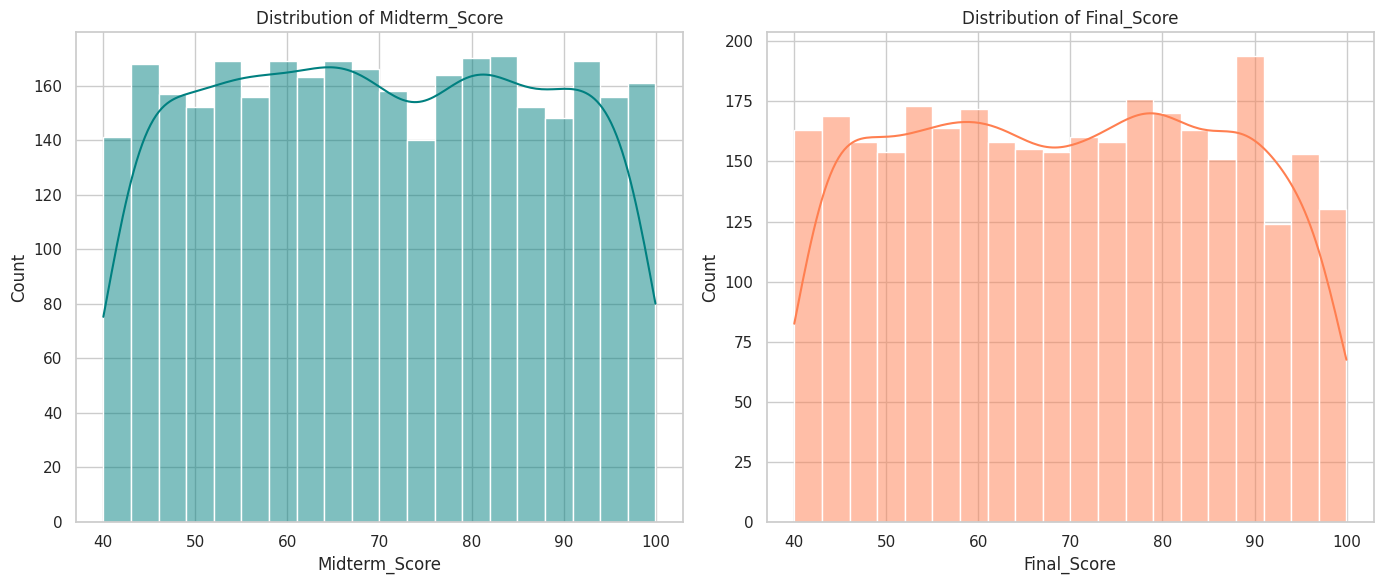

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('/content/Dataset.csv')

# Find matching columns for midterm and final scores
midterm_col = [col for col in df.columns if 'midterm' in col.lower() or 'mid_term' in col.lower() or 'mid term' in col.lower()]
final_col = [col for col in df.columns if 'final' in col.lower()]

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot Midterm Score Distribution
if midterm_col:
    col_name = midterm_col[0]
    sns.histplot(data=df, x=col_name, ax=axes[0], kde=True, color='teal', bins=20)
    axes[0].set_title(f'Distribution of {col_name}')
    axes[0].set_xlabel(col_name)
    axes[0].set_ylabel('Count')
else:
    # Fallback to general numerical column if specific match not found
    axes[0].text(0.5, 0.5, 'Midterm column not found', ha='center', va='center')
    axes[0].set_title('Midterm Score Distribution')

# Plot Final Score Distribution
if final_col:
    col_name = final_col[0]
    sns.histplot(data=df, x=col_name, ax=axes[1], kde=True, color='coral', bins=20)
    axes[1].set_title(f'Distribution of {col_name}')
    axes[1].set_xlabel(col_name)
    axes[1].set_ylabel('Count')
else:
    axes[1].text(0.5, 0.5, 'Final column not found', ha='center', va='center')
    axes[1].set_title('Final Score Distribution')

plt.tight_layout()
plt.show()

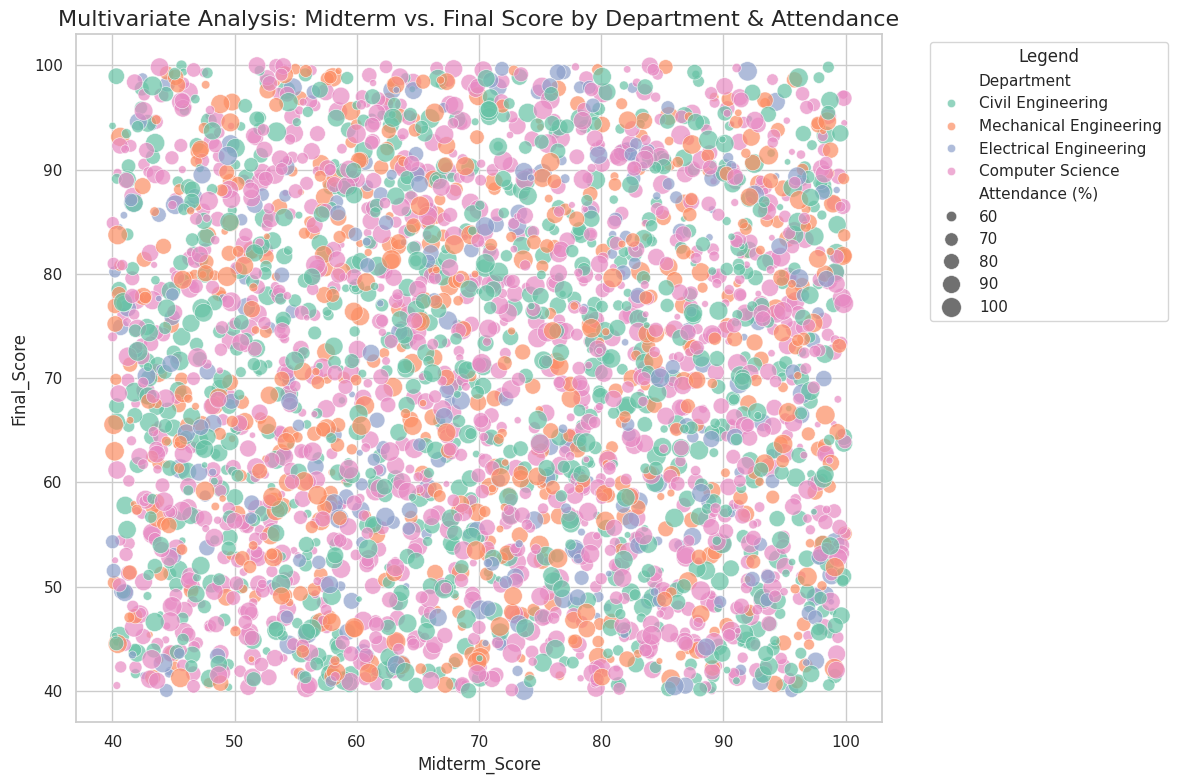

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('/content/Dataset.csv')

# Dynamic column mapping
midterm_col = [col for col in df.columns if 'midterm' in col.lower() or 'mid_term' in col.lower() or 'mid term' in col.lower()][0]
final_col = [col for col in df.columns if 'final' in col.lower()][0]
dept_col = [col for col in df.columns if 'dept' in col.lower() or 'department' in col.lower()][0]
att_col = [col for col in df.columns if 'attend' in col.lower() or 'attendance' in col.lower()][0]

# Set plotting theme
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 8))

# Create multivariate scatter plot
sns.scatterplot(
    data=df,
    x=midterm_col,
    y=final_col,
    hue=dept_col,
    size=att_col,
    sizes=(20, 200),
    alpha=0.7,
    palette="Set2"
)

plt.title('Multivariate Analysis: Midterm vs. Final Score by Department & Attendance', fontsize=16)
plt.xlabel(midterm_col, fontsize=12)
plt.ylabel(final_col, fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Legend')
plt.tight_layout()
plt.show()

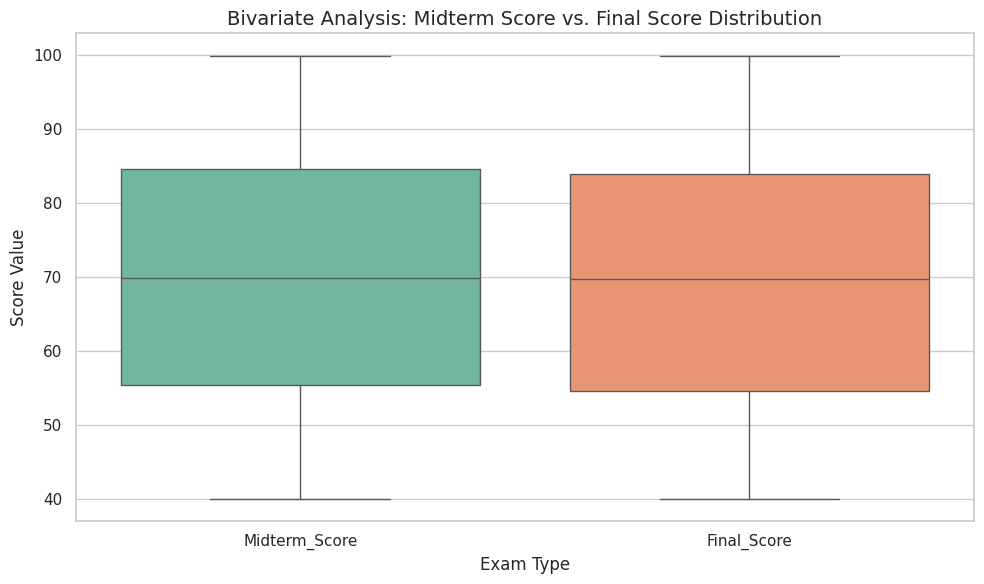

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('/content/Dataset.csv')

# Dynamic column mapping
midterm_col = [col for col in df.columns if 'midterm' in col.lower() or 'mid_term' in col.lower() or 'mid term' in col.lower()][0]
final_col = [col for col in df.columns if 'final' in col.lower()][0]

# Melt the dataframe to have a single column for scores and a column identifying Midterm/Final
melted_df = df.melt(
    value_vars=[midterm_col, final_col],
    var_name='Exam_Type',
    value_name='Score'
)

# Set plotting theme
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Create boxplot comparing Midterm and Final Scores
sns.boxplot(
    data=melted_df,
    x='Exam_Type',
    y='Score',
    palette='Set2',
    hue='Exam_Type',
    legend=False
)

plt.title('Bivariate Analysis: Midterm Score vs. Final Score Distribution', fontsize=14)
plt.xlabel('Exam Type', fontsize=12)
plt.ylabel('Score Value', fontsize=12)
plt.tight_layout()
plt.show()

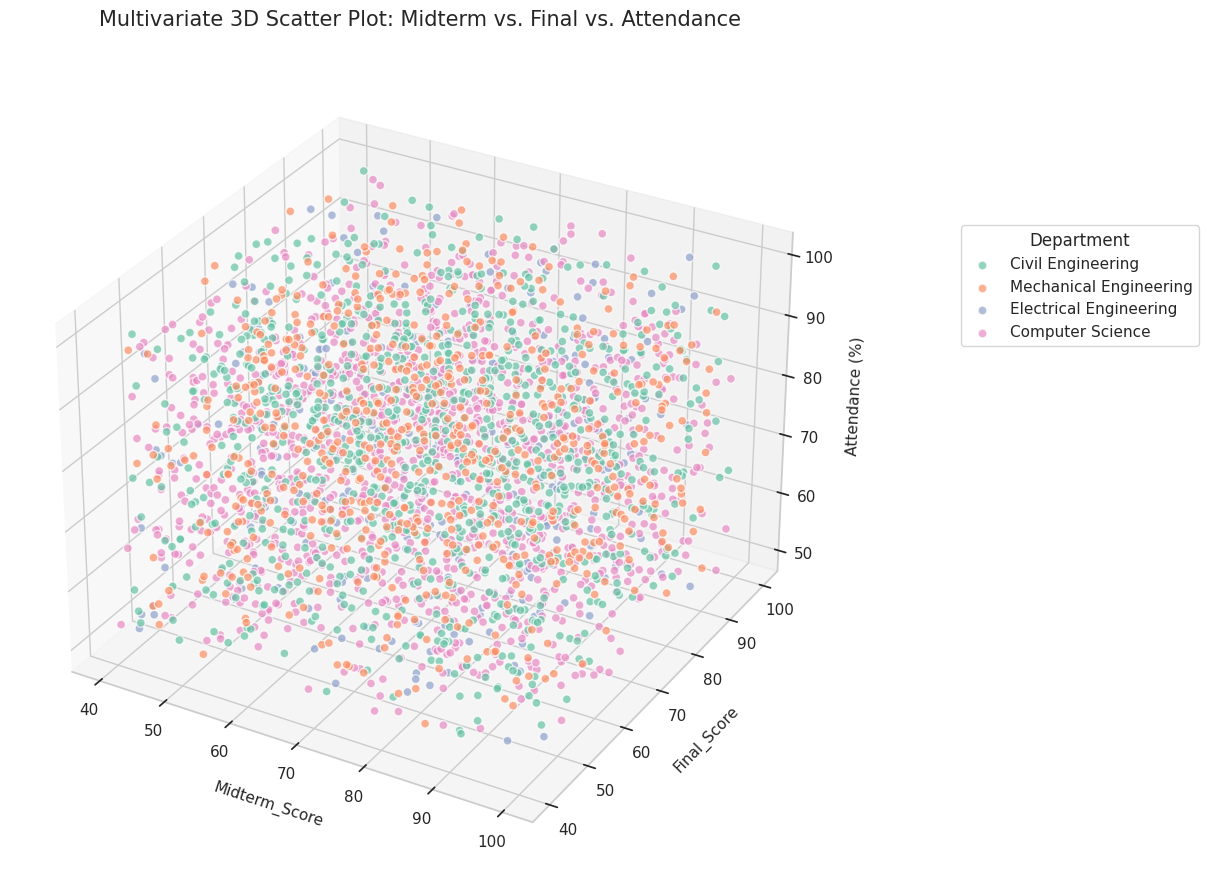

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import seaborn as sns

# Load dataset
df = pd.read_csv('/content/Dataset.csv')

# Dynamic column mapping
midterm_col = [col for col in df.columns if 'midterm' in col.lower() or 'mid_term' in col.lower() or 'mid term' in col.lower()][0]
final_col = [col for col in df.columns if 'final' in col.lower()][0]
dept_col = [col for col in df.columns if 'dept' in col.lower() or 'department' in col.lower()][0]
att_col = [col for col in df.columns if 'attend' in col.lower() or 'attendance' in col.lower()][0]

# Setup the figure and 3D axes
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

# Assign colors based on Department categories
unique_depts = df[dept_col].unique()
colors = sns.color_palette('Set2', len(unique_depts))
dept_color_map = dict(zip(unique_depts, colors))

# Plot each department category separately to build a legend
for dept in unique_depts:
    subset = df[df[dept_col] == dept]
    ax.scatter(
        subset[midterm_col],
        subset[final_col],
        subset[att_col],
        label=dept,
        color=dept_color_map[dept],
        alpha=0.7,
        edgecolors='w',
        s=40
    )

# Label axes
ax.set_xlabel(midterm_col, fontsize=11, labelpad=10)
ax.set_ylabel(final_col, fontsize=11, labelpad=10)
ax.set_zlabel(att_col, fontsize=11, labelpad=10)

# Set title and legend
ax.set_title('Multivariate 3D Scatter Plot: Midterm vs. Final vs. Attendance', fontsize=15, pad=20)
ax.legend(title=dept_col, bbox_to_anchor=(1.15, 0.8), loc='upper left')

plt.tight_layout()
plt.show()

In [13]:
import pandas as pd
import plotly.express as px

# Load dataset
df = pd.read_csv('/content/Dataset.csv')

# Dynamic column mapping
midterm_col = [col for col in df.columns if 'midterm' in col.lower() or 'mid_term' in col.lower() or 'mid term' in col.lower()][0]
final_col = [col for col in df.columns if 'final' in col.lower()][0]
dept_col = [col for col in df.columns if 'dept' in col.lower() or 'department' in col.lower()][0]
att_col = [col for col in df.columns if 'attend' in col.lower() or 'attendance' in col.lower()][0]

# Sort dataset by Attendance so the animation flows smoothly from low to high attendance
df_sorted = df.sort_values(by=att_col)

# Create an interactive animated scatter plot using Plotly
fig = px.scatter(
    df_sorted,
    x=midterm_col,
    y=final_col,
    animation_frame=att_col,
    animation_group="Student_ID",
    color=dept_col,
    hover_name="Student_ID",
    range_x=[df_sorted[midterm_col].min() - 5, df_sorted[midterm_col].max() + 5],
    range_y=[df_sorted[final_col].min() - 5, df_sorted[final_col].max() + 5],
    title="Interactive Animated Scatter: Midterm vs Final Scores (Animated by Attendance %)",
    labels={midterm_col: "Midterm Score", final_col: "Final Score"},
    template="plotly_white"
)

# Improve layout and animation controls speed using lowercase enum values
fig.update_layout(
    updatemenus=[{
        "buttons": [
            {
                "args": [None, {"frame": {"duration": 100, "redraw": True}, "fromcurrent": True}],
                "label": "Play",
                "method": "animate"
            },
            {
                "args": [[None], {"frame": {"duration": 0, "redraw": True}, "mode": "immediate", "transition": {"duration": 0}}],
                "label": "Pause",
                "method": "animate"
            }
        ],
        "direction": "left",
        "pad": {"r": 10, "t": 87},
        "showactive": False,
        "type": "buttons",
        "x": 0.1,
        "xanchor": "right",
        "y": 0,
        "yanchor": "top"
    }]
)

fig.show()

In [14]:
import pandas as pd
import plotly.express as px

# Load dataset
df = pd.read_csv('/content/Dataset.csv')

# Dynamic column mapping
midterm_col = [col for col in df.columns if 'midterm' in col.lower() or 'mid_term' in col.lower() or 'mid term' in col.lower()][0]
final_col = [col for col in df.columns if 'final' in col.lower()][0]
dept_col = [col for col in df.columns if 'dept' in col.lower() or 'department' in col.lower()][0]
att_col = [col for col in df.columns if 'attend' in col.lower() or 'attendance' in col.lower()][0]

# Sort dataset by Attendance so the animation progresses smoothly
df_sorted = df.sort_values(by=att_col)

# Create a faceted, animated scatter plot by Department
fig = px.scatter(
    df_sorted,
    x=midterm_col,
    y=final_col,
    animation_frame=att_col,
    animation_group="Student_ID",
    color=dept_col,
    facet_col=dept_col,
    hover_name="Student_ID",
    range_x=[df_sorted[midterm_col].min() - 5, df_sorted[midterm_col].max() + 5],
    range_y=[df_sorted[final_col].min() - 5, df_sorted[final_col].max() + 5],
    title="Temporal & Multivariate Animated Scatter: Midterm vs Final Scores by Department",
    labels={midterm_col: "Midterm Score", final_col: "Final Score"},
    template="plotly_white"
)

# Ensure lower-case 'animate' method is used for layout button configuration
fig.update_layout(
    updatemenus=[{
        "buttons": [
            {
                "args": [None, {"frame": {"duration": 120, "redraw": True}, "fromcurrent": True}],
                "label": "Play",
                "method": "animate"
            },
            {
                "args": [[None], {"frame": {"duration": 0, "redraw": True}, "mode": "immediate", "transition": {"duration": 0}}],
                "label": "Pause",
                "method": "animate"
            }
        ],
        "direction": "left",
        "pad": {"r": 10, "t": 87},
        "showactive": False,
        "type": "buttons",
        "x": 0.1,
        "xanchor": "right",
        "y": 0,
        "yanchor": "top"
    }]
)

fig.show()

In [16]:
import pandas as pd
import plotly.graph_objects as go
import seaborn as sns

# Load dataset
df = pd.read_csv('/content/Dataset.csv')

# Dynamic column mapping
midterm_col = [col for col in df.columns if 'midterm' in col.lower() or 'mid_term' in col.lower() or 'mid term' in col.lower()][0]
final_col = [col for col in df.columns if 'final' in col.lower()][0]
dept_col = [col for col in df.columns if 'dept' in col.lower() or 'department' in col.lower()][0]
att_col = [col for col in df.columns if 'attend' in col.lower() or 'attendance' in col.lower()][0]
part_col = [col for col in df.columns if 'particip' in col.lower()][0] if any('particip' in col.lower() for col in df.columns) else None

# Columns available for Y-axis switching
y_options = [final_col, att_col]
if part_col:
    y_options.append(part_col)

# Set up color mapping for departments
unique_depts = df[dept_col].unique()
colors = sns.color_palette('Set2', len(unique_depts)).as_hex()
dept_color_map = dict(zip(unique_depts, colors))

# Create a Figure
fig = go.Figure()

# Add traces for each department
for dept in unique_depts:
    dept_df = df[df[dept_col] == dept]
    fig.add_trace(
        go.Scatter(
            x=dept_df[midterm_col],
            y=dept_df[final_col],
            mode='markers',
            name=dept,
            marker=dict(
                color=dept_color_map[dept],
                size=8,
                opacity=0.7,
                line=dict(width=0.5, color='white')
            ),
            text=dept_df['Student_ID'] if 'Student_ID' in df.columns else None,
            hovertemplate="<b>%{text}</b><br>Midterm: %{x}<br>Y-Value: %{y}<extra></extra>"
        )
    )

# Build dropdown buttons
buttons = []
for y_col in y_options:
    # Define what data is updated for each trace when this option is selected
    y_data_list = []
    for dept in unique_depts:
        dept_df = df[df[dept_col] == dept]
        y_data_list.append(dept_df[y_col])

    button = dict(
        method="restyle",
        args=[{"y": y_data_list}],
        label=y_col.replace('_', ' ')
    )
    buttons.append(button)

# Update layout with dropdown menu and labels (using valid 'weight' property for bold)
fig.update_layout(
    title="Interactive Multivariate Scatter: Midterm Score vs. Selectable Y-Axis Metric",
    xaxis_title="Midterm Score",
    yaxis_title=final_col.replace('_', ' '),
    template="plotly_white",
    updatemenus=[{
        "buttons": buttons,
        "direction": "down",
        "showactive": True,
        "x": 0.15,
        "xanchor": "left",
        "y": 1.15,
        "yanchor": "top"
    }],
    annotations=[
        dict(
            text="Select Y-Axis Metric:",
            showarrow=False,
            x=0,
            y=1.12,
            xref="paper",
            yref="paper",
            font=dict(size=12, weight="bold")
        )
    ],
    legend_title=dept_col
)

fig.show()